In [14]:
import json
import os

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

In [15]:
with open('../results/eval_attn_logit_std.jsonl') as f:
    rows = [json.loads(line) for line in f]

rows.sort(key=lambda r: int(r['revision'].replace('step', '')))

steps = np.array([int(r['revision'].replace('step', '')) for r in rows])
# attn_std: (n_steps, n_layers, num_heads)
attn_std = np.array([r['attn_logit_std'] for r in rows])
attn_entropy = np.array([r['attn_entropy'] for r in rows])

n_layers, num_heads = attn_std.shape[1], attn_std.shape[2]

# Dynamic time tau
def lr_scheduler(step, total_steps=143000):
    if step < total_steps * 0.01:
        return step / (total_steps * 0.01)
    progress = (step - total_steps * 0.01) / (total_steps * 0.99)
    return 0.5 * (1.0 + np.cos(np.pi * progress)) * 0.9 + 0.1

cache_path = '../cache/lrs_cache.npy'
if os.path.exists(cache_path):
    lrs = np.load(cache_path)
else:
    lrs = np.array([lr_scheduler(s) for s in range(1, 143001)])
    np.save(cache_path, lrs)

cumsum = np.cumsum(lrs)
tau = cumsum[steps - 1]

print(f'Steps: {steps}')
print(f'attn_std shape: {attn_std.shape}  (n_steps, n_layers, num_heads)')
print(f'attn_entropy shape: {attn_entropy.shape}  (n_steps, n_layers, num_heads)')

Steps: [  128   256   512  1000  2000  3000  6000 12000 16000 32000 48000 79000]
attn_std shape: (12, 12, 12)  (n_steps, n_layers, num_heads)
attn_entropy shape: (12, 12, 12)  (n_steps, n_layers, num_heads)


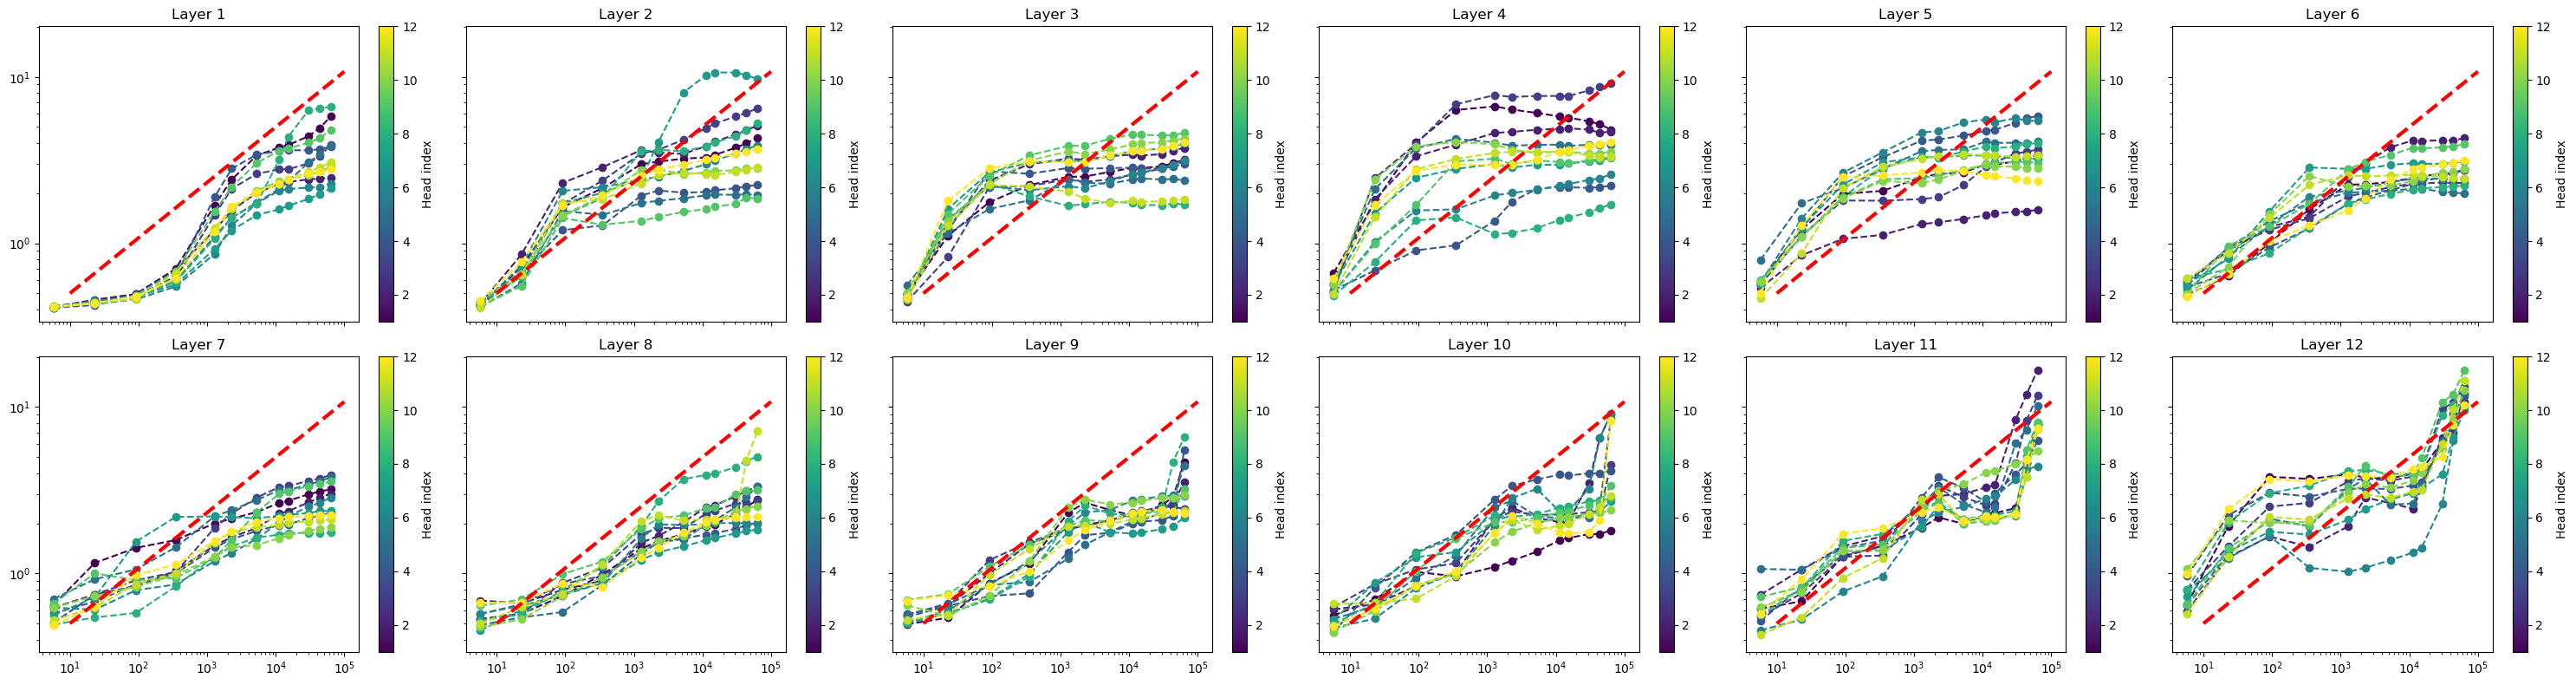

In [16]:
cmap = plt.get_cmap('viridis')
norm = mcolors.Normalize(vmin=1, vmax=num_heads)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig, axs = plt.subplots(2, n_layers // 2, figsize=(n_layers * 2.5, 8), sharex = True, sharey = True)
flat_axs = axs.flatten()
for layer in range(n_layers):
    for head in range(num_heads):
        flat_axs[layer].plot(tau, attn_std[:, layer, head], 'o--', color=cmap(head / (num_heads - 1)))
    flat_axs[layer].plot([1e+1,1e+5], [.5, .5 * 1e+4 ** (1/3)], 'r--', linewidth=3)
    flat_axs[layer].set_xscale('log')
    flat_axs[layer].set_yscale('log')
    flat_axs[layer].set_title(f'Layer {layer+1}')
    fig.colorbar(sm, ax=flat_axs[layer], label='Head index')
plt.tight_layout()

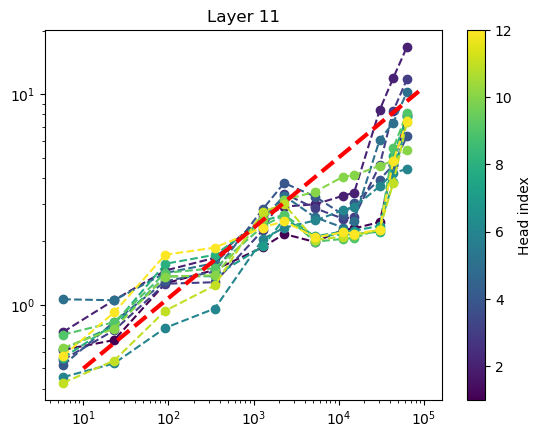

In [17]:
# layer 11 looks special
layer = 10
for head in range(num_heads):
    plt.plot(tau, attn_std[:, layer, head], 'o--', color=cmap(head / (num_heads - 1)))
plt.plot([1e+1,1e+5], [.5, .5 * 1e+4 ** (1/3)], 'r--', linewidth=3)
plt.xscale('log')
plt.yscale('log')
plt.title(f'Layer {layer+1}')
plt.colorbar(sm, ax=plt.gca(), label='Head index')

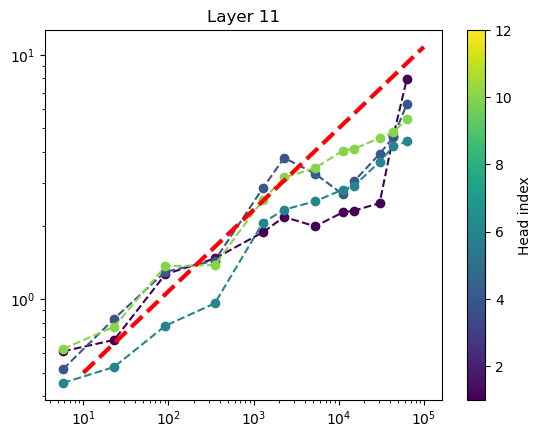

In [18]:
# layer 11 looks special
layer = 10
for head in [0,3,5,9]:
    plt.plot(tau, attn_std[:, layer, head], 'o--', color=cmap(head / (num_heads - 1)))
plt.plot([1e+1,1e+5], [.5, .5 * 1e+4 ** (1/3)], 'r--', linewidth=3)
plt.xscale('log')
plt.yscale('log')
plt.title(f'Layer {layer+1}')
plt.colorbar(sm, ax=plt.gca(), label='Head index')

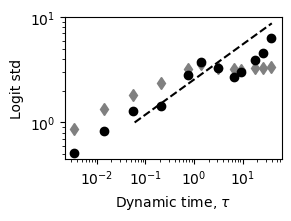

In [35]:
plt.figure(figsize=(2.8, 2.1), constrained_layout=True)
head_logit_std = np.array([ 0.8715683,  1.3299577,  1.8162096,  2.3492937,  3.2422955,
        3.583397 ,  3.2818153,  3.1874068,  3.1717563,  3.2560227,
        3.2707646,  3.3620856])
plt.plot(tau * 6e-4, head_logit_std, 'd', color='grey')
plt.plot(tau * 6e-4, attn_std[:,10,3], 'ko')
#plt.plot(tau * 1.2e-4, attn_std[:,23,5], 'ko')
#plt.plot(tau * 1.2e-4, attn_std[:,23,16], 'ko')
plt.plot([6e-2,4e+1], [1, 1 * (2e+1/3e-2) ** (1/3)], 'k--')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'Dynamic time, $\tau$')
plt.ylabel('Logit std')
plt.savefig('../figures/logit_std_160m.pdf')

In [34]:
attn_entropy[:,10,3]

array([6.44952753, 6.1843121 , 5.24551104, 4.95157064, 3.49451149,
       2.42668434, 2.21369546, 2.07547677, 1.736183  , 1.11484181,
       1.19694125, 0.794506  ])

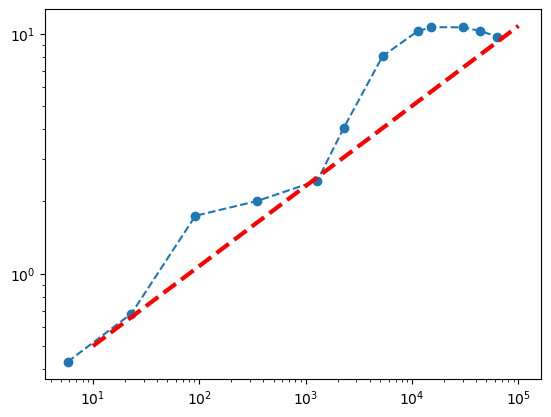

In [6]:
for head in [6]:
    plt.plot(tau, attn_std[:, 1, head], 'o--')
plt.plot([1e+1,1e+5], [.5, .5 * 1e+4 ** (1/3)], 'r--', linewidth=3)
plt.xscale('log')
plt.yscale('log')

The last sharp increase in the norm may be related to smaller lr or river valley? Related to the sharp decrease of loss at the end?

Evaluate our own checkpoints and then larger Pythia models?

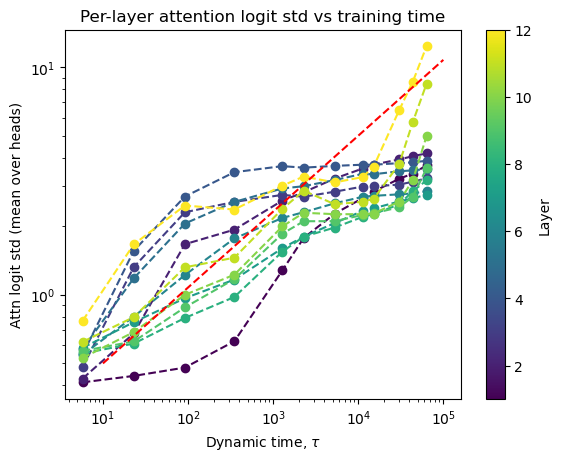

In [7]:
# Mean over heads: (n_steps, n_layers)
std_mean_heads = attn_std.mean(axis=2)

cmap = plt.get_cmap('viridis')
for layer in range(n_layers):
    plt.plot(tau, std_mean_heads[:, layer], 'o--', color=cmap(layer / (n_layers - 1)))
#plt.plot(tau, std_mean_heads.mean(axis=1), 'k-', label='mean over layers')
plt.plot([1e+1,1e+5], [.5, .5 * 10000 ** (1/3)], 'r--')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'Dynamic time, $\tau$')
plt.ylabel('Attn logit std (mean over heads)')
plt.title('Per-layer attention logit std vs training time')

norm = mcolors.Normalize(vmin=1, vmax=n_layers)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
plt.colorbar(sm, ax=plt.gca(), label='Layer')
#plt.legend()
#plt.tight_layout()

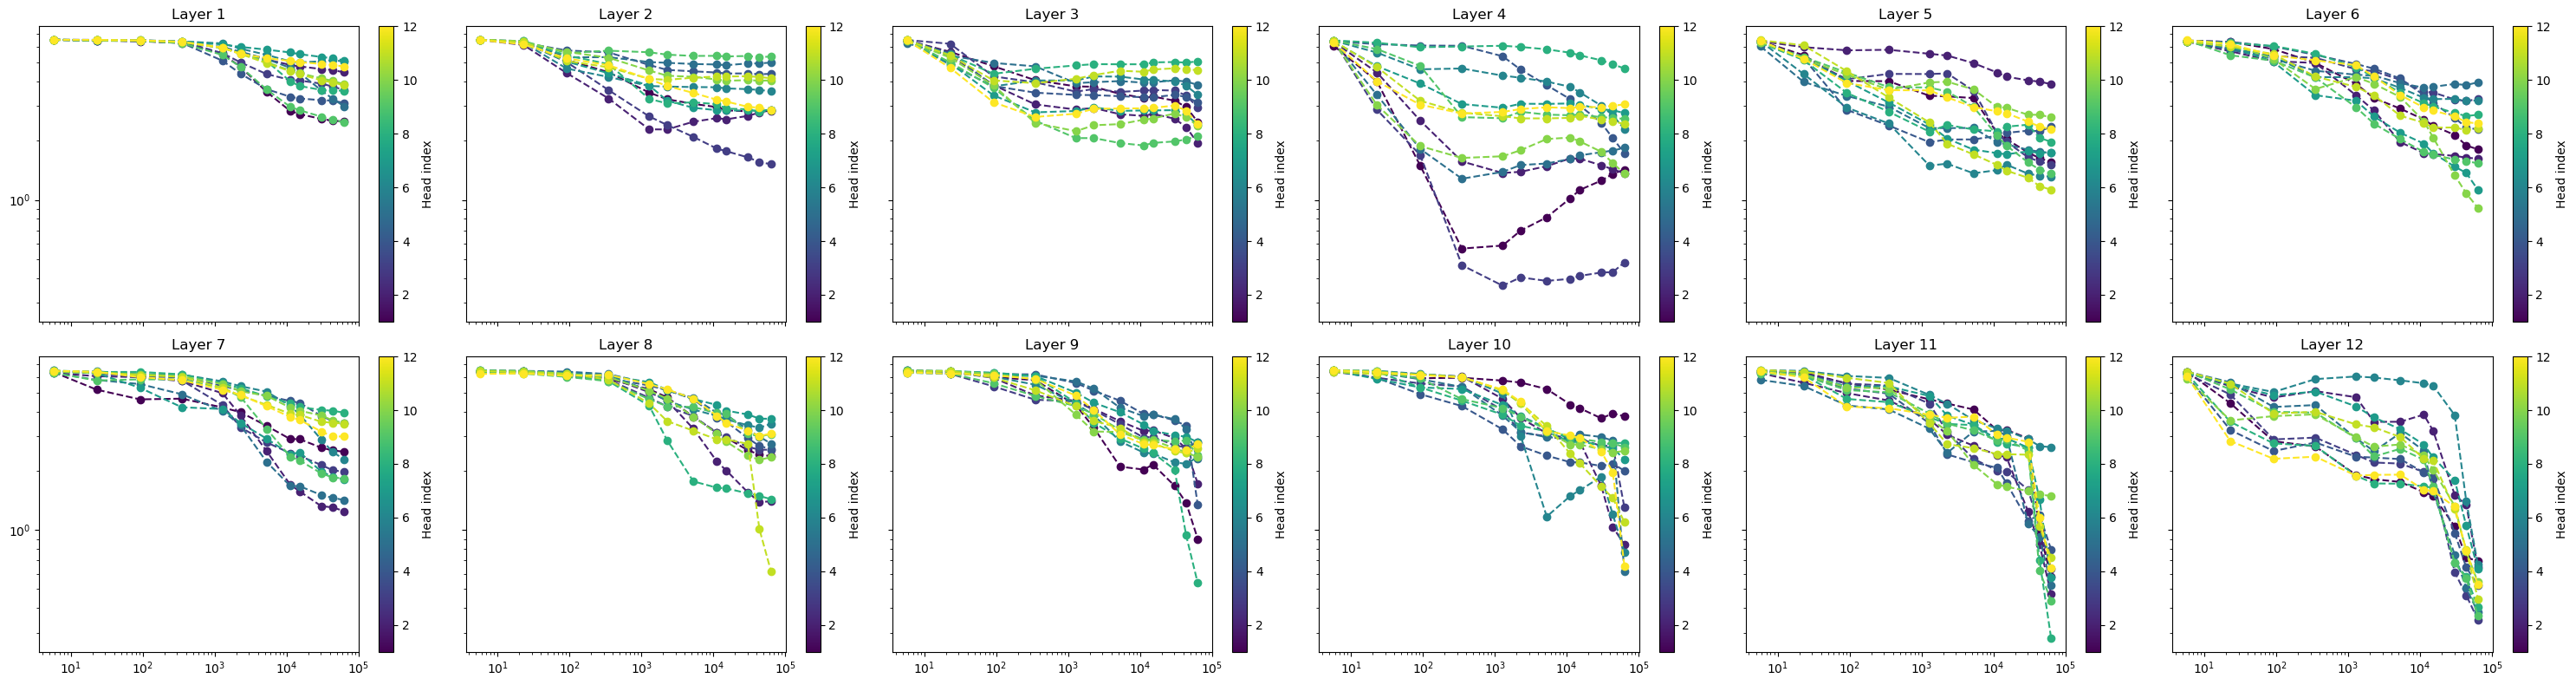

In [8]:
cmap = plt.get_cmap('viridis')
norm = mcolors.Normalize(vmin=1, vmax=num_heads)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig, axs = plt.subplots(2, n_layers // 2, figsize=(n_layers * 2.5, 8), sharex = True, sharey = True)
flat_axs = axs.flatten()
for layer in range(n_layers):
    for head in range(num_heads):
        flat_axs[layer].plot(tau, attn_entropy[:, layer, head], 'o--', color=cmap(head / (num_heads - 1)))
    #flat_axs[layer].plot([1e+1,1e+5], [.5, .5 * 1e+4 ** (1/3)], 'r--', linewidth=3)
    flat_axs[layer].set_xscale('log')
    flat_axs[layer].set_yscale('log')
    flat_axs[layer].set_title(f'Layer {layer+1}')
    fig.colorbar(sm, ax=flat_axs[layer], label='Head index')
plt.tight_layout()

In [9]:
def H_gaussian(beta, n_samples = 1024):
    logits = np.random.normal(loc=0.0, scale=beta, size=(n_samples,))
    prob = np.exp(logits - np.max(logits))
    prob /= np.sum(prob)
    return -np.sum(prob * np.log(prob + 1e-12))

H_theory = []
for ctx_len in range(2, 2048):
    beta = np.sqrt(2 * np.log(ctx_len))
    H_theory.append(H_gaussian(beta, ctx_len))
H_theory = np.array(H_theory)
H_t_mean = np.mean(H_theory)
H_head = np.array([H_gaussian(np.sqrt(2 * np.log(32000)), 32000) for i in range(500)]).mean()

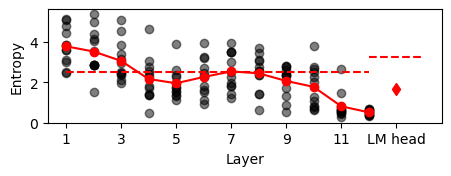

In [13]:
# last point
plt.figure(figsize=(4.4, 1.65), constrained_layout=True)
plt.plot(range(1, n_layers + 1), attn_entropy[-1, :, :], 'o', color='k', alpha = 0.5)
plt.plot(range(1, n_layers + 1), attn_entropy[-1, :, :].mean(axis=1), 'o-', color='r')
plt.plot(range(1, n_layers + 1), H_t_mean * np.ones(n_layers), 'r--')
plt.plot([13], [1.69], 'd', color='r')
plt.plot([12,14], [H_head, H_head], 'r--')
plt.xticks([i for i in range(1, n_layers + 1, 2)]+[13], labels=[str(i) for i in range(1, n_layers + 1, 2)] + ['LM head'])
plt.ylim(0, None)
plt.ylabel(r"Entropy")
plt.xlabel(r"Layer")
plt.savefig('../figures/attn_entropy_160m.png', dpi=300)